In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [143]:
data = pd.read_csv("SMSSpamCollection",
     sep='\t',
      header=None,
       names=['label', 'text']  )

In [144]:
data.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [145]:
data.shape

(5572, 2)

In [146]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   text    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [147]:
data.duplicated().sum()

np.int64(403)

In [148]:
data.drop_duplicates(inplace=True)

In [149]:
data.shape

(5169, 2)

In [150]:
data.value_counts("label")

,count
label,
ham,4516
spam,653


In [151]:
data.dtypes

,0
label,object
text,object


In [152]:
data.isnull().sum()


,0
label,0
text,0


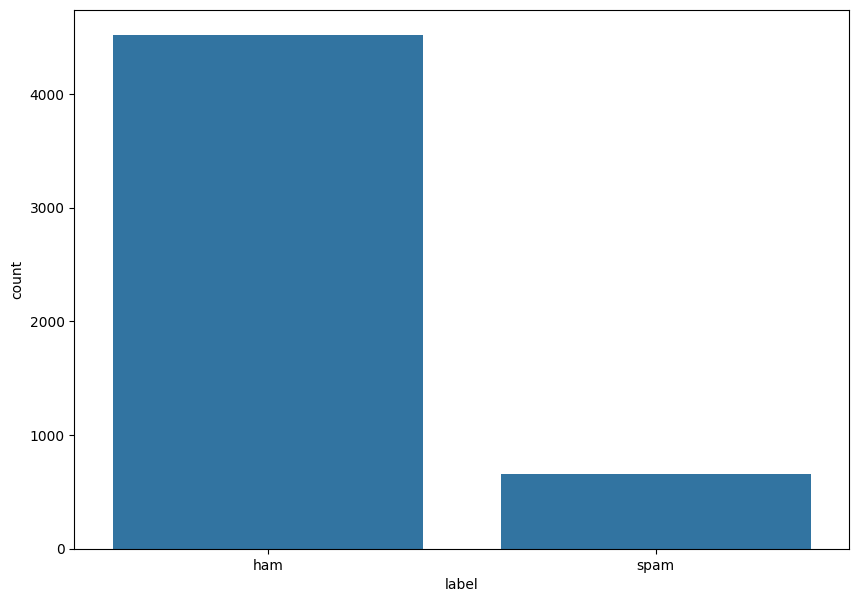

In [153]:
plt.figure(figsize=(10,7))
sns.countplot(x = "label",data=data)
plt.show()

In [154]:
X = data["text"]
y = data["label"]


In [155]:
X.shape

(5169,)

In [156]:
y.shape

(5169,)

In [157]:
X_train,X_test,y_train,y_test=train_test_split(X,y, test_size = 0.2,stratify=y, random_state = 42)

In [158]:
X_train.shape


(4135,)

In [159]:
X_test.shape


(1034,)

In [160]:
y_train.shape


(4135,)

In [161]:



y_test.shape


(1034,)

In [162]:
tfi = TfidfVectorizer()
X_train_tfi = tfi.fit_transform(X_train)
X_test_tfi = tfi.transform(X_test)

In [163]:
X_train_tfi.shape


(4135, 7680)

In [164]:
X_test_tfi.shape

(1034, 7680)

In [165]:
nb_model = MultinomialNB()

In [166]:
nb_model.fit(X_train_tfi, y_train)

MultinomialNB()

In [167]:
y_pred_nb= nb_model.predict(X_test_tfi)

In [168]:
y_pred_nb

array(['ham', 'ham', 'ham', ..., 'spam', 'ham', 'ham'],
      shape=(1034,), dtype='<U4')

In [169]:
accuracy = accuracy_score(y_test, y_pred_nb)
print("Model Accuracy:", accuracy)

Model Accuracy: 0.9526112185686654


In [170]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_nb))

              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.63      0.77       131

    accuracy                           0.95      1034
   macro avg       0.97      0.81      0.87      1034
weighted avg       0.96      0.95      0.95      1034



In [171]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred_nb)

In [172]:
print("Confusion Matrix:", cm)

Confusion Matrix: [[903   0]
 [ 49  82]]


In [173]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression()


In [174]:
lr_model.fit(X_train_tfi, y_train)

LogisticRegression()

In [175]:
y_pred_lr = lr_model.predict(X_test_tfi)

In [176]:
y_pred_lr

array(['ham', 'ham', 'ham', ..., 'spam', 'ham', 'ham'],
      shape=(1034,), dtype=object)

In [177]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_accuracy

0.9642166344294004

In [178]:
y_test

,label
5318,ham
5281,ham
2459,ham
1305,ham
5083,ham
...,...
1120,spam
3068,ham
813,spam
1560,ham


In [179]:
y_pred_lr


array(['ham', 'ham', 'ham', ..., 'spam', 'ham', 'ham'],
      shape=(1034,), dtype=object)

In [180]:
clfn_report=classification_report(y_test, y_pred_lr)
print(clfn_report)

              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       0.96      0.75      0.84       131

    accuracy                           0.96      1034
   macro avg       0.96      0.87      0.91      1034
weighted avg       0.96      0.96      0.96      1034



In [181]:
from sklearn.svm import LinearSVC
svc_model = LinearSVC()
svc_model.fit(X_train_tfi, y_train)


LinearSVC()

In [182]:
y_pred_scv = svc_model.predict(X_test_tfi)

In [183]:
y_pred_scv

array(['ham', 'ham', 'ham', ..., 'spam', 'ham', 'ham'],
      shape=(1034,), dtype=object)

In [184]:
scv_accuracy = accuracy_score(y_test, y_pred_scv)
scv_accuracy

0.9816247582205029

In [185]:
clfn_report_svc=classification_report(y_test, y_pred_scv)
print(clfn_report_svc)

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.97      0.89      0.92       131

    accuracy                           0.98      1034
   macro avg       0.98      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



In [186]:
report_svc= classification_report(y_test, y_pred_scv, output_dict=True)

In [187]:
report_svc

{'ham': {'precision': 0.9835886214442013,
  'recall': 0.9955703211517165,
  'f1-score': 0.9895432030820033,
  'support': 903.0},
 'spam': {'precision': 0.9666666666666667,
  'recall': 0.8854961832061069,
  'f1-score': 0.9243027888446215,
  'support': 131.0},
 'accuracy': 0.9816247582205029,
 'macro avg': {'precision': 0.975127644055434,
  'recall': 0.9405332521789117,
  'f1-score': 0.9569229959633123,
  'support': 1034.0},
 'weighted avg': {'precision': 0.9814447374249972,
  'recall': 0.9816247582205029,
  'f1-score': 0.9812777347405168,
  'support': 1034.0}}

In [188]:
report_svc = classification_report(
    y_test,
    y_pred_scv,
    output_dict=True
)

In [189]:
type(report_svc)

dict

In [190]:
report_svc['spam']['precision']

0.9666666666666667

In [191]:
report_svc['spam']['recall']

0.8854961832061069

In [192]:
report_svc['spam']['f1-score']

0.9243027888446215

In [193]:
report_lr = classification_report(
    y_test,
    y_pred_lr,
    output_dict=True
)

In [194]:
report_lr['spam']['precision']


0.9607843137254902

In [195]:
report_lr['spam']['recall']


0.7480916030534351

In [196]:
report_lr['spam']['f1-score']

0.8412017167381974

In [197]:
report_nb = classification_report(
    y_test,
    y_pred_nb,
    output_dict=True
)

In [198]:
report_nb['spam']['precision']


1.0

In [199]:
report_nb['spam']['recall']

0.6259541984732825

In [200]:
report_nb['spam']['f1-score']

0.7699530516431925

In [201]:
model_comparison = {}

In [202]:
model_comparison["Naive Bayes"] = {
    "precision": report_nb["spam"]["precision"],
    "recall": report_nb["spam"]["recall"],
    "f1_score": report_nb["spam"]["f1-score"]
}

In [203]:
report_nb

{'ham': {'precision': 0.9485294117647058,
  'recall': 1.0,
  'f1-score': 0.9735849056603774,
  'support': 903.0},
 'spam': {'precision': 1.0,
  'recall': 0.6259541984732825,
  'f1-score': 0.7699530516431925,
  'support': 131.0},
 'accuracy': 0.9526112185686654,
 'macro avg': {'precision': 0.9742647058823529,
  'recall': 0.8129770992366412,
  'f1-score': 0.8717689786517849,
  'support': 1034.0},
 'weighted avg': {'precision': 0.9550503470246899,
  'recall': 0.9526112185686654,
  'f1-score': 0.9477862858574265,
  'support': 1034.0}}

In [204]:
model_comparison

{'Naive Bayes': {'precision': 1.0,
  'recall': 0.6259541984732825,
  'f1_score': 0.7699530516431925}}

In [205]:
report_nb = report_nb["spam"]


In [206]:
model_comparison["Logistic Regression"] = {
    "precision": report_lr["spam"]["precision"],
    "recall": report_lr["spam"]["recall"],
    "f1_score": report_lr["spam"]["f1-score"]
}

In [207]:
model_comparison

{'Naive Bayes': {'precision': 1.0,
  'recall': 0.6259541984732825,
  'f1_score': 0.7699530516431925},
 'Logistic Regression': {'precision': 0.9607843137254902,
  'recall': 0.7480916030534351,
  'f1_score': 0.8412017167381974}}

In [208]:
model_comparison["Linear SVM"] = {
    "precision": report_svc["spam"]["precision"],
    "recall": report_svc["spam"]["recall"],
    "f1_score": report_svc["spam"]["f1-score"]
}

In [209]:
model_comparison

{'Naive Bayes': {'precision': 1.0,
  'recall': 0.6259541984732825,
  'f1_score': 0.7699530516431925},
 'Logistic Regression': {'precision': 0.9607843137254902,
  'recall': 0.7480916030534351,
  'f1_score': 0.8412017167381974},
 'Linear SVM': {'precision': 0.9666666666666667,
  'recall': 0.8854961832061069,
  'f1_score': 0.9243027888446215}}

In [210]:
comparison_df=pd.DataFrame.from_dict(model_comparison, orient="index")

In [211]:
comparison_df

,precision,recall,f1_score
Naive Bayes,1.000000,0.625954,0.769953
Logistic Regression,0.960784,0.748092,0.841202
Linear SVM,0.966667,0.885496,0.924303


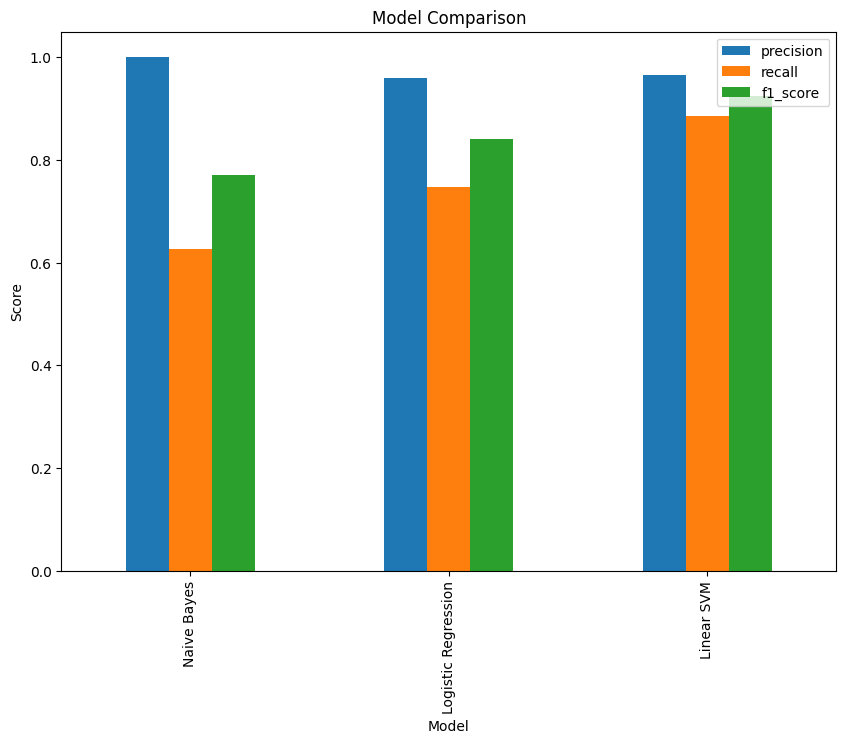

In [213]:
comparison_df.plot(kind = "bar", figsize=(10,7))
plt.xlabel("Model")
plt.ylabel("Score")
plt.title("Model Comparison")
plt.show()

In [214]:
confusion_matrix(y_test,y_pred_scv)

array([[899,   4],
       [ 15, 116]])

In [215]:
new_messages = [
    "Hey, are we meeting tomorrow at 10 AM?",
    "Congratulations! You won a free prize. Claim your cash reward now!"
]

In [216]:
new_messages

['Hey, are we meeting tomorrow at 10 AM?',
 'Congratulations! You won a free prize. Claim your cash reward now!']

In [218]:
new_messages_tfi = tfi.transform(new_messages)

In [219]:
new_messages_tfi.shape

(2, 7680)

In [220]:
new_predictions = svc_model.predict(new_messages_tfi)

In [221]:
new_predictions

array(['ham', 'spam'], dtype=object)

In [222]:
import joblib

In [223]:
joblib.dump(svc_model, 'sms_spam_model.pkl')


['sms_spam_model.pkl']

In [226]:
joblib.dump(tfi, 'tfidf_vectorizer.pkl')

['tfidf_vectorizer.pkl']

In [228]:
import os

In [230]:
os.listdir()

['.config',
 'SMSSpamCollection',
 'sms_spam_model.pkl',
 'tfidf_vectorizer.pkl',
 'sample_data']

In [232]:
loaded_model = joblib.load('sms_spam_model.pkl')

In [234]:
loaded_model

LinearSVC()

In [236]:
loaded_tfi = joblib.load('tfidf_vectorizer.pkl')

In [237]:
loaded_tfi

TfidfVectorizer()

In [239]:
new_messages_tfi_loaded = loaded_tfi.transform(new_messages)

In [240]:
new_messages_tfi_loaded.shape

(2, 7680)

In [241]:
loaded_predictions = loaded_model.predict(new_messages_tfi_loaded)

print(loaded_predictions)


['ham' 'spam']
